# Ronda 008b — investigación y resultados
Análisis de una ejecución cerrada. Todos los scores locales intervienen en selección.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
from IPython.display import display, Markdown
if not Path('reports/registro_008b.json').exists(): os.chdir('..')
r = json.loads(Path('reports/registro_008b.json').read_text())
display(Markdown(Path('reports/resumen_008b.md').read_text()))
display(pd.read_csv('reports/resultados_cv_008b.csv'))
display(pd.read_csv('reports/criterios_008b.csv'))
display(r['historical'])

# Ronda 008b: estrategias investigadas y ejecutadas

## Resultado

Candidata seleccionada: **nbsvm**. CSV creado: **True**.

| Modelo | F1 macro OOF medio | Diferencia frente a 007 | Brecha entrenamiento-validación | Folds ganados |
|---|---:|---:|---:|---:|
| nbsvm | 0.892841 | +0.015556 | 0.107165 | 9/9 |
| chi2_50 | 0.889295 | +0.012009 | 0.109054 | 9/9 |
| joint_w15 | 0.877792 | +0.000506 | 0.121858 | 5/9 |
| ref007 | 0.877286 | +0.000000 | 0.122364 | — |
| connector_identity | 0.877041 | -0.000245 | 0.122803 | 4/9 |
| joint_w05 | 0.875240 | -0.002045 | 0.124407 | 2/9 |

Los valores son medias de F1 macro calculado sobre predicciones fuera de fold (OOF) en tres particiones de desarrollo. La brecha es la media de F1 de entrenamiento menos F1 de validación por fold. La brecha menor no prueba ausencia de sobreajuste.

## Qué se implementó

- `ref007`: reproducción del modelo 007, TF-IDF con posición por tercios y LinearSVC C=2.
- `joint_w05` y `joint_w15`: pesos 0,5 y 1,5 para tercios en el mismo TF-IDF y normalización final L2. El control de peso 1 reproduce numéricamente 007.
- `connector_identity`: características que unen la identidad del conector con palabras de su cláusula, sin reglas manuales de etiqueta.
- `chi2_50`: selección supervisada del 50 % de características dentro de cada fold, seguida de normalización y LinearSVC C=2.
- `nbsvm`: presencia binaria de las características de discurso de 007, ponderación logarítmica Naive Bayes por clase frente al resto y tres SVM C=1; gana la clase de mayor margen. Es una adaptación multiclase del artículo, sin su interpolación opcional.

Investigación y fuentes: [detalle](investigacion_008b.md), [Wang y Manning, 2012](https://aclanthology.org/P12-2018/), [selección de características](https://scikit-learn.org/stable/modules/feature_selection.html), [prevención de fuga](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage). Los recursos externos aportan métodos, nunca ejemplos de entrenamiento.

## Protocolo y decisión

>=7/9 folds ganados; delta medio OOF >=0.003; brecha media no mayor; no perder en137. No alterar después de ver resultados.

Se usaron las mismas semillas 711, 1237 y 2003 de la ronda 008 para comparar con 007. La ronda anterior se conserva. Las candidatas elegibles se compararon también en la partición histórica 137:

- chi2_50: 0.885014, referencia 007: 0.877822; supera puerta: True.
- nbsvm: 0.888992, referencia 007: 0.877822; supera puerta: True.

Tras cerrar la selección se ajustó la candidata elegida con los 12000 ejemplos etiquetados. Se exportaron `models/modelo_008.joblib` y `submissions/submission_008.csv`. El CSV conserva el orden del ejemplo de envío, con 3000 identificadores únicos, columnas `id,answer` y etiquetas válidas. No se ha enviado a la plataforma.

## Sobreajuste y límites

Solo 9600 ejemplos de desarrollo participan en selección. Los 2400 del antiguo test local no se reutilizan para seleccionar; ya habían sido observados en la historia del proyecto y no se presentan como prueba virgen. Tras decidir el modelo, incluirlos en el ajuste final para predecir eval es legítimo.

Se mantienen grupos disjuntos por texto normalizado. Vocabulario, IDF, chi² y cocientes Naive Bayes se aprenden únicamente con la parte de entrenamiento de cada fold. Las etiquetas de validación solo sirven para calcular F1 macro. Eval no interviene en estos ajustes ni decisiones.

Todas estas métricas son de selección: se han explorado repetidamente los mismos datos. Los folds y semillas no son observaciones independientes; no se atribuye significación estadística a contar victorias. El criterio fijo reduce decisiones oportunistas en esta ronda, pero no elimina el sobreajuste de selección acumulado. Tampoco se garantiza ausencia de duplicados semánticos con una normalización simple.

La captura aportada registra 0,88888 público para 007. No verifica la fórmula oficial de la métrica. El score público de 008 es desconocido y el F1 local no promete 0,90 público. El entrenamiento casi perfecto, incluso con una brecha menor, exige conservar esta cautela.

La conclusión causal del informe anterior 008 era demasiado fuerte: separar bloques altera su normalización, pero no el IDF de características comunes con igual frecuencia documental. El control real de esta ronda comprueba esta igualdad; no se concluye que toda ponderación de tercios sea inútil.

## Reproducibilidad

Tiempo del experimento: 289.4 segundos. Artefactos anteriores intactos: True.

Desde la raíz: `.venv/bin/python -m src.experimento_008b`. El registro existente impide repetir accidentalmente la ronda. Generar este informe y notebook: `.venv/bin/python -m src.informe_008b`.

Los hashes, versiones, resultados por fold, predicciones OOF y criterios están en los archivos `registro_008b.json`, `folds_008b.csv`, `predicciones_oof_008b.csv` y `criterios_008b.csv` de reports. El notebook reproduce el análisis guardado; no vuelve a entrenar.


,name,seed,oof_f1,fold_mean,fold_std,train_mean,gap
0,ref007,711,0.879730,0.879714,0.004451,0.999555,0.119840
1,joint_w05,711,0.876800,0.876788,0.001969,0.999555,0.122767
2,joint_w15,711,0.878704,0.878686,0.002722,0.999703,0.121017
3,connector_identity,711,0.878531,0.878519,0.003761,0.999802,0.121283
4,chi2_50,711,0.889951,0.889931,0.004288,0.998417,0.108486
5,nbsvm,711,0.892946,0.892935,0.005144,1.000000,0.107065
6,ref007,1237,0.875045,0.875028,0.004381,0.999604,0.124577
7,joint_w05,1237,0.874138,0.874123,0.005099,0.999654,0.125531
8,joint_w15,1237,0.877224,0.877205,0.006666,0.999604,0.122399
9,connector_identity,1237,0.877328,0.877316,0.004464,0.999852,0.122536


,name,mean_f1_gain,folds_won,mean_gap_change,passes
0,joint_w05,-0.002045,2,0.002043,False
1,joint_w15,0.000506,5,-0.000506,False
2,connector_identity,-0.000245,4,0.000439,False
3,chi2_50,0.012009,9,-0.013310,True
4,nbsvm,0.015556,9,-0.015199,True


{'chi2_50': {'candidate': 0.8850143931603528,
  'reference': 0.8778223683005089,
  'passes': True},
 'nbsvm': {'candidate': 0.8889920274199711,
  'reference': 0.8778223683005089,
  'passes': True}}

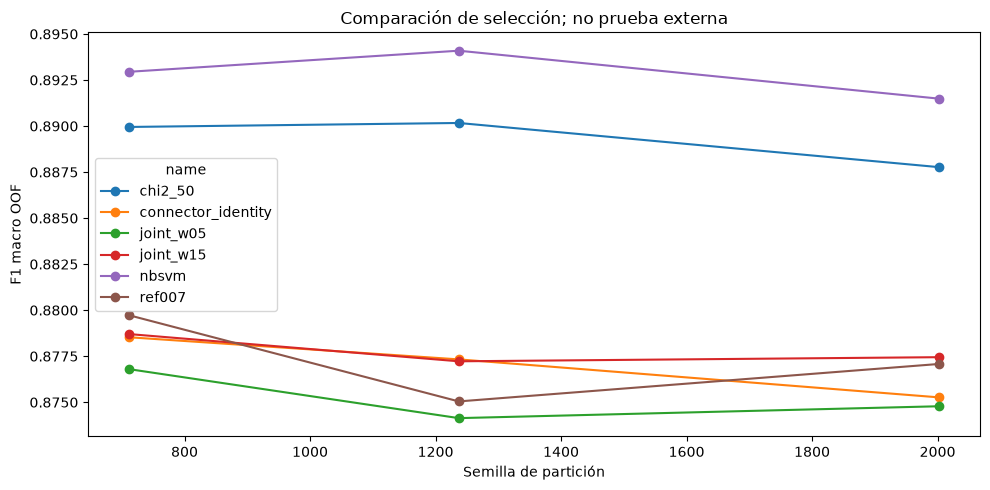

,name,seed,fold,train_f1,validation_f1,gap,iterations,seconds
0,ref007,711,0,0.999406,0.884958,0.114449,60,4.500720
1,ref007,711,1,0.999703,0.880109,0.119594,60,4.494241
2,ref007,711,2,0.999555,0.874077,0.125478,61,4.550638
3,joint_w05,711,0,0.999406,0.877568,0.121838,60,4.591083
4,joint_w05,711,1,0.999703,0.878713,0.120990,60,4.585599
...,...,...,...,...,...,...,...,...
58,chi2_50,137,1,0.998219,0.880751,0.117469,67,4.541514
59,chi2_50,137,2,0.998219,0.886819,0.111400,68,4.523086
60,nbsvm,137,0,1.000000,0.890890,0.109110,149,3.690338
61,nbsvm,137,1,1.000000,0.885951,0.114049,145,3.671219


In [2]:
import matplotlib.pyplot as plt
cv = pd.read_csv('reports/resultados_cv_008b.csv')
main = cv[cv.seed.isin(r['plan']['seeds'])]
ax = main.pivot(index='seed', columns='name', values='oof_f1').plot(marker='o', figsize=(10,5))
ax.set(xlabel='Semilla de partición', ylabel='F1 macro OOF', title='Comparación de selección; no prueba externa')
plt.tight_layout()
plt.savefig('reports/comparacion_008b.png', dpi=160)
plt.show()
display(pd.read_csv('reports/folds_008b.csv'))

In [3]:
display(r['source_sha256'])
print('Artefactos anteriores intactos:', r['old_artifacts_unchanged'])
if r['submission_created']:
    display(r['artifacts_sha256'])
    display(pd.read_csv('submissions/submission_008.csv').head())
else:
    print(r['decision'])

{'src/experimento_008b.py': '2c600778222e2d296ae936bbd4985d75edf893c36df25e2fb18b21c2b14975cf',
 'src/modelos_008b.py': '71774e20c9b62a8f63310156b6d498165168d99dd82980919d9d9481c93f5d91',
 'src/features_007b.py': '32168dc3045b8b146e3260ddfb8b04c3153e1210ade017050ec2243fe7c3daa3',
 'reports/particiones.csv': 'd90cbd30a92a366298a66f2322df4869694798392f19b9c0978dbecac104a931'}

Artefactos anteriores intactos: True


{'models/modelo_008.joblib': '60d8b233c1dd7c6ea828a32b8216116a5558ee5ada26844b44011fc57e47b1bc',
 'submissions/submission_008.csv': '39863146032500fface58110e08137e25985376d349bc1821c0b0190c42db41b'}

,id,answer
0,0,neutral
1,1,positivo
2,2,neutral
3,3,neutral
4,4,neutral
